# ML441 Assignment 4: Ensemble Learning for Network Intrusion Classification

This notebook evaluates two ensemble approaches on the Assignment 2 UNSW-NB15 dataset:

1. **TabM**: a parameter-efficient ensemble of *k* multilayer perceptrons that share weights
   through BatchEnsemble layers.
2. **Stacking**: a heterogeneous ensemble in which a multinomial logistic-regression
   meta-learner combines out-of-fold class probabilities from k-nearest neighbours, a
   classification tree and TabM.

Every model is compared with the Assignment 2 baselines on the **same** grouped, stratified
outer folds, so each fold-level difference is paired.

Expensive results (base-learner probabilities, TabM tuning) are cached in `output/`, so a
rerun takes minutes. Setting `ML441_EXPERIMENT_MODE=smoke` runs every cell on a 10% subset of
predictor groups with short training, writing to `output/smoke/` instead.

## 0.1 Environment and reproducibility

The random seed matches Assignment 2 (21). Package versions are recorded because the
report must list the libraries used. `cuml-cu12` runs k-NN on the GPU; `torch` and `tabm`
run the neural-network ensemble.

In [1]:
import copy
import hashlib
import importlib.metadata as metadata
import itertools
import json
import os
import platform
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tabm
import torch
import torch.nn.functional as F
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, OneHotEncoder, OrdinalEncoder, QuantileTransformer, RobustScaler, StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.validation import check_is_fitted

SMOKE = os.environ.get("ML441_EXPERIMENT_MODE", "full") == "smoke"
RANDOM_STATE = 21
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

A2_DIR = Path("../Assignment2")
DATA_PATH = A2_DIR / "networkTraffic.csv"
FEATURES_PATH = A2_DIR / "features.csv"
A2_OUTPUT_DIR = A2_DIR / "output"
OUTPUT_DIR = Path("output/smoke" if SMOKE else "output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PACKAGES = [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib",
    "torch", "tabm", "rtdl_num_embeddings", "cuml-cu12",
]
environment = pd.DataFrame(
    [("python", sys.version.split()[0]), ("platform", platform.platform())]
    + [(package, metadata.version(package)) for package in PACKAGES]
    + [
        ("cuda_runtime", torch.version.cuda),
        ("gpu", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none"),
        ("random_seed", RANDOM_STATE),
    ],
    columns=["component", "value"],
)
environment.to_csv(OUTPUT_DIR / "ass4_environment.csv", index=False)
print(f"Experiment mode: {'smoke' if SMOKE else 'full'}")
display(environment)

Experiment mode: full


,component,value
0,python,3.12.3
1,platform,Linux-6.18.33.2-microsoft-standard-WSL2-x86_64...
2,numpy,2.4.6
3,pandas,3.0.3
4,scipy,1.18.1
5,scikit-learn,1.9.0
6,matplotlib,3.11.1
7,torch,2.13.0+cu129
8,tabm,0.0.3
9,rtdl_num_embeddings,0.0.12


## 0.2 Data loading and target labels

The dataset is read from the Assignment 2 folder rather than copied, and its SHA-256
digest is compared with the digest Assignment 2 recorded. A match proves that both
assignments model the identical file. The literal `?` marks missing values. Target
codes are decoded to attack names by matching class counts to the published
UNSW-NB15 benchmark, as in Assignment 2.

In [2]:
for path in (DATA_PATH, FEATURES_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Required input not found: {path.resolve()}")

data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
a2_provenance = pd.read_csv(A2_OUTPUT_DIR / "ass2_input_provenance.csv").set_index("input_file")
if data_sha256 != a2_provenance.loc[DATA_PATH.name, "sha256"]:
    raise ValueError("networkTraffic.csv differs from the file Assignment 2 modelled.")

raw_df = pd.read_csv(DATA_PATH, na_values=["?"])
TARGET_COLUMN = raw_df.columns[-1]
NOMINAL_COLUMNS = ["proto", "state", "service"]
if raw_df.shape[1] - 1 != 43 or TARGET_COLUMN != "attack_cat":
    raise ValueError("Expected 43 descriptive features followed by the attack_cat target.")

# Assignment 2 established this code-to-name mapping from exact published class counts.
class_mapping = pd.read_csv(A2_OUTPUT_DIR / "ass2_class_mapping.csv")
CLASS_NAME_BY_CODE = dict(zip(class_mapping["attack_code"], class_mapping["attack_class"]))
observed_counts = raw_df[TARGET_COLUMN].dropna().astype(int).value_counts()
expected_counts = class_mapping.set_index("attack_code")["observed_count"]
if not observed_counts.sort_index().equals(expected_counts.sort_index()):
    raise ValueError("Target code counts do not match the Assignment 2 class mapping.")
CLASS_ORDER = [CLASS_NAME_BY_CODE[code] for code in sorted(CLASS_NAME_BY_CODE)]

analysis_df = raw_df.dropna(subset=[TARGET_COLUMN]).copy()
analysis_df[TARGET_COLUMN] = analysis_df[TARGET_COLUMN].astype(int).map(CLASS_NAME_BY_CODE)
X = analysis_df.drop(columns=["id", TARGET_COLUMN])
y = analysis_df[TARGET_COLUMN]
NUMERIC_COLUMNS = X.select_dtypes(include=np.number).columns.tolist()
predictor_groups = pd.util.hash_pandas_object(X, index=False).rename("predictor_group")

assert set(NUMERIC_COLUMNS) | set(NOMINAL_COLUMNS) == set(X.columns)
assert not set(NUMERIC_COLUMNS) & set(NOMINAL_COLUMNS)
print(f"Rows: {len(analysis_df):,} (missing targets removed: {len(raw_df) - len(analysis_df):,})")
print(f"Predictors: {X.shape[1]} ({len(NUMERIC_COLUMNS)} numeric, {len(NOMINAL_COLUMNS)} nominal)")
print(f"Dataset SHA-256 matches Assignment 2: {data_sha256[:16]}...")
display(class_mapping[["attack_code", "attack_class", "observed_count"]])

Rows: 257,673 (missing targets removed: 0)
Predictors: 42 (39 numeric, 3 nominal)
Dataset SHA-256 matches Assignment 2: acde2c646b55c9c6...


,attack_code,attack_class,observed_count
0,0,Normal,93000
1,1,Reconnaissance,13987
2,2,Backdoor,2329
3,3,DoS,16353
4,4,Exploits,44525
5,5,Analysis,2677
6,6,Fuzzers,24246
7,7,Worms,174
8,8,Shellcode,1511
9,9,Generic,58871


## 0.3 Label conflicts

After removing the identifier, rows with identical values for all 42 predictors form a group.
A group has conflicting labels when those rows belong to more than one class. The counts below
describe that ambiguity and justify keeping whole groups in the same evaluation fold.


In [ ]:
label_groups = pd.DataFrame({"group": predictor_groups.to_numpy(), "target": y.to_numpy()})
labels_per_group = label_groups.groupby("group")["target"].transform("nunique")
label_conflict = pd.DataFrame(
    {
        "rows": y.value_counts().reindex(CLASS_ORDER),
        "share_in_conflicting_groups": (
            labels_per_group.gt(1).groupby(label_groups["target"]).mean().reindex(CLASS_ORDER)
        ),
    }
)
label_conflict.index.name = "attack_class"
label_conflict.to_csv(OUTPUT_DIR / "ass4_label_conflicts.csv")
print(f"Rows in label-conflicting groups: {labels_per_group.gt(1).mean():.1%}")
display(label_conflict.round(3))


## 0.4 Preprocessing reused from Assignment 2

`TrafficPreprocessor` is copied unchanged from Assignment 2. It is fitted inside each
fold only, so no statistics from a test fold reach training. It encodes missing nominal
values as an explicit `__missing__` level, one-hot encodes `proto`, `state` and
`service`, and optionally scales numeric features, groups rare levels and prunes
near-duplicate numeric features. k-NN and the MLP-based models need scaling; the tree
does not.

In [4]:
class TrafficPreprocessor(BaseEstimator, TransformerMixin):
    '''Fold-fitted preprocessing used directly by the two notebook pipelines.'''

    def __init__(
        self,
        numeric_columns,
        nominal_columns,
        *,
        scaling="standard",
        min_frequency=None,
        correlation_threshold=0.995,
        selector_k=None,
        missing_label="__missing__",
    ):
        self.numeric_columns = numeric_columns
        self.nominal_columns = nominal_columns
        self.scaling = scaling
        self.min_frequency = min_frequency
        self.correlation_threshold = correlation_threshold
        self.selector_k = selector_k
        self.missing_label = missing_label

    @staticmethod
    def _encoder(min_frequency):
        handle_unknown = "infrequent_if_exist" if min_frequency is not None else "ignore"
        try:
            return OneHotEncoder(
                handle_unknown=handle_unknown,
                min_frequency=min_frequency,
                sparse_output=False,
                dtype=np.float32,
            )
        except TypeError:  # Compatibility with older scikit-learn releases.
            return OneHotEncoder(
                handle_unknown=handle_unknown,
                min_frequency=min_frequency,
                sparse=False,
                dtype=np.float32,
            )

    def _validate_frame(self, frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("TrafficPreprocessor requires a pandas DataFrame.")
        required = set(self.numeric_columns) | set(self.nominal_columns)
        missing = sorted(required.difference(frame.columns))
        if missing:
            raise KeyError(f"Missing preprocessing columns: {missing}")

    def fit(self, frame, target=None):
        self._validate_frame(frame)
        if self.scaling not in {None, "standard", "robust"}:
            raise ValueError("scaling must be None, 'standard', or 'robust'.")
        if self.correlation_threshold is not None and not (
            0 <= self.correlation_threshold <= 1
        ):
            raise ValueError("correlation_threshold must be between 0 and 1, or None.")

        numeric = frame.loc[:, self.numeric_columns]
        if numeric.isna().to_numpy().any():
            raise ValueError("Numeric predictors contain unexpected missing values.")

        kept_numeric = list(self.numeric_columns)
        dropped_numeric = []
        if self.correlation_threshold is not None and len(kept_numeric) > 1:
            absolute_correlation = numeric.corr().abs()
            kept_numeric = []
            for column in self.numeric_columns:
                if any(
                    absolute_correlation.loc[column, keeper]
                    >= self.correlation_threshold
                    for keeper in kept_numeric
                ):
                    dropped_numeric.append(column)
                else:
                    kept_numeric.append(column)

        self.kept_numeric_features_ = kept_numeric
        self.dropped_numeric_features_ = dropped_numeric
        numeric_values = frame.loc[:, kept_numeric].to_numpy(dtype=np.float32)
        if self.scaling == "standard":
            self.scaler_ = StandardScaler().fit(numeric_values)
        elif self.scaling == "robust":
            self.scaler_ = RobustScaler().fit(numeric_values)
        else:
            self.scaler_ = None

        self.nominal_imputer_ = SimpleImputer(
            strategy="constant",
            fill_value=self.missing_label,
            keep_empty_features=True,
        )
        nominal_imputed = self.nominal_imputer_.fit_transform(
            frame.loc[:, self.nominal_columns]
        )
        self.categorical_encoder_ = self._encoder(self.min_frequency)
        nominal_encoded = self.categorical_encoder_.fit_transform(nominal_imputed)
        numeric_transformed = (
            self.scaler_.transform(numeric_values)
            if self.scaler_ is not None
            else numeric_values
        )
        combined = np.hstack(
            [
                np.asarray(numeric_transformed),
                np.asarray(nominal_encoded),
            ]
        ).astype(np.float32, copy=False)
        feature_names = np.concatenate(
            [
                np.asarray(self.kept_numeric_features_, dtype=object),
                self.categorical_encoder_.get_feature_names_out(self.nominal_columns),
            ]
        )

        if self.selector_k is None:
            self.selector_ = None
            self.feature_names_out_ = feature_names
        else:
            if target is None:
                raise ValueError("target is required when selector_k is enabled.")
            selected_k = min(int(self.selector_k), combined.shape[1])
            if selected_k < 1:
                raise ValueError("selector_k must be at least 1 or None.")
            self.selector_ = SelectKBest(score_func=f_classif, k=selected_k).fit(
                combined, target
            )
            self.feature_names_out_ = feature_names[self.selector_.get_support()]

        self.n_features_out_ = len(self.feature_names_out_)
        return self

    def transform(self, frame):
        check_is_fitted(
            self,
            ["kept_numeric_features_", "categorical_encoder_", "n_features_out_"],
        )
        self._validate_frame(frame)
        numeric_values = frame.loc[:, self.kept_numeric_features_].to_numpy(
            dtype=np.float32
        )
        if self.scaler_ is not None:
            numeric_values = self.scaler_.transform(numeric_values)
        nominal_imputed = self.nominal_imputer_.transform(
            frame.loc[:, self.nominal_columns]
        )
        nominal_encoded = self.categorical_encoder_.transform(nominal_imputed)
        combined = np.hstack(
            [
                np.asarray(numeric_values),
                np.asarray(nominal_encoded),
            ]
        ).astype(np.float32, copy=False)
        return (
            self.selector_.transform(combined)
            if self.selector_ is not None
            else combined
        )

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "feature_names_out_")
        return np.asarray(self.feature_names_out_, dtype=object)

## 0.5 Outer folds shared with Assignment 2

The outer split repeats Assignment 2's `StratifiedGroupKFold` with five folds, shuffling
and seed 21. Groups are identical predictor vectors, so exact copies never sit on both
sides of a split. The assertion compares every row's fold with the fold Assignment 2
saved. A mismatch would make the paired comparison with Assignment 2 invalid, so the
notebook stops if one occurs.

In [5]:
OUTER_FOLDS = 5
INNER_FOLDS = 3

outer_cv = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
outer_fold = pd.Series(0, index=X.index, name="outer_fold")
for fold, (_, test_positions) in enumerate(outer_cv.split(X, y, predictor_groups), start=1):
    outer_fold.iloc[test_positions] = fold
assert outer_fold.gt(0).all(), "Every row must belong to exactly one outer test fold."
assert predictor_groups.groupby(outer_fold.to_numpy()).unique().explode().is_unique, (
    "A predictor group was split across outer folds."
)

for a2_model in ("knn", "tree"):
    a2_folds = pd.read_csv(
        A2_OUTPUT_DIR / f"ass2_{a2_model}_oof_predictions_full.csv",
        usecols=["source_index", "outer_fold"],
    ).set_index("source_index")["outer_fold"]
    mismatched = int((a2_folds.reindex(X.index) != outer_fold).sum())
    assert mismatched == 0, f"{mismatched:,} rows differ from the A2 {a2_model} folds."
print("Outer folds match Assignment 2 exactly for both baseline models.")

outer_fold.rename_axis("source_index").to_csv(OUTPUT_DIR / "ass4_outer_folds.csv")
fold_summary = pd.crosstab(outer_fold, y).reindex(columns=CLASS_ORDER)
fold_summary["total"] = fold_summary.sum(axis=1)
display(fold_summary)

if SMOKE:
    # Keep every tenth predictor group (about 10% of rows) so a smoke run exercises every cell in minutes.
    keep = (predictor_groups % 10 == 0).to_numpy()
    X, y, predictor_groups, outer_fold = X[keep], y[keep], predictor_groups[keep], outer_fold[keep]
    print(f"Smoke mode: {len(X):,} rows kept")
FOLDS = range(1, OUTER_FOLDS + 1)

Outer folds match Assignment 2 exactly for both baseline models.


attack_cat,Normal,Reconnaissance,Backdoor,DoS,Exploits,Analysis,Fuzzers,Worms,Shellcode,Generic,total
outer_fold,,,,,,,,,,,
1,18600,2797,466,3271,8905,536,4849,35,302,11774,51535
2,18600,2797,465,3271,8905,535,4849,35,302,11775,51534
3,18600,2797,466,3270,8905,536,4850,35,302,11774,51535
4,18600,2798,466,3271,8905,535,4849,34,303,11774,51535
5,18600,2798,466,3270,8905,535,4849,35,302,11774,51534


## Questions set before evaluation

The questions, grids and predictions below were fixed **before** any ensemble was trained or
evaluated. Tuning is meant to answer them, not only to pick a model.

**TabM.** Candidates are scored by macro F1 on one grouped, stratified 20% hold-out of each
outer-train fold, which also drives early stopping. Stage 1 searches capacity at *k* = 32;
stage 2 changes one factor at a time from the stage-1 winner. The fold's selected model is
the candidate with the highest hold-out macro F1.

| # | Question | Grid | Prediction |
|---|---|---|---|
| Q1 | How much does ensemble size improve macro F1 over a single MLP? | *k* ∈ {1, 4, 8, 32} | Most of the gain arrives by *k* = 8. |
| Q2 | Does class-weighted cross-entropy raise minority-class F1 (Worms, Shellcode) without hurting the majority classes? | unweighted, balanced weights | Minority recall rises, but precision on Normal and Generic falls. |
| Q3 | Do members trained on **different** minibatches (closer to bagging) beat members sharing one batch? | shared, distinct | Little difference: weight scaling already supplies the diversity. |
| Q4 | Which capacity suits data with label conflicts; does it favour stronger regularisation? | width {256, 512} × depth {2, 3} × dropout {0, 0.1, 0.2} × learning rate {1e-3, 2e-3} | Dropout > 0 wins; capacity matters little. |

**Stacking.** The meta-learner is tuned by grouped 3-fold cross-validation on a 30,000-row
stratified sample of each outer-train fold, as in Assignment 2, over representation
{probabilities, log-probabilities, one-hot labels} × C {0.01, 0.1, 1, 10} × class weight
{none, balanced}.

| # | Question | Prediction |
|---|---|---|
| Q5 | Does the learned meta-learner (S2) beat soft voting over the same three learners (V2)? | Yes, slightly: soft voting cannot down-weight the weak k-NN. |
| Q6 | Does adding TabM (S2 against S1) add useful diversity? Measured by score and by base-learner error correlation. | Yes: TabM's errors correlate less with the tree's than k-NN's do. |
| Q7 | Does the meta-learner learn to trust k-NN on DoS and Analysis, where k-NN beat the tree in Assignment 2? | Yes: k-NN's own-class coefficients are largest for those two classes. |
| Q8 | Which meta-feature representation works best, and why? | Probabilities or log-probabilities; one-hot labels discard confidence. |

**Class-specific performance.**

| # | Question | Prediction |
|---|---|---|
| Q9 | How do Backdoor, DoS and Analysis F1 change relative to the earlier tree? | Gains are limited and occur mainly on the other named attack classes. |

Five paired folds limit the statistics: a two-sided Wilcoxon signed-rank test on *n* = 5 cannot
go below *p* = 0.0625. Results report the mean ± standard deviation, all five paired
differences, and the Nadeau–Bengio corrected resampled *t*-test.

# Phase 1: Assignment 2 baselines as stacking inputs

Stacking trains a meta-learner on the base learners' predictions. Those predictions must come
from models that never saw the row being predicted; otherwise the meta-learner sees
over-confident training predictions and learns to trust the most overfitted base learner.

Each baseline is rebuilt from the parameters Assignment 2 selected **for that outer fold**.
Assignment 2 chose them by inner cross-validation on that fold's outer-train rows only, so
reusing them inside the inner folds below leaks nothing from the outer test fold. k-NN uses
scikit-learn rather than cuML for the reason shown in Section 1.4.

## 1.1 Out-of-fold probabilities

`out_of_fold_probabilities` takes a `fit_predict` function, so the same loop serves the
baselines, TabM and the leakage test. For outer fold *f* it returns:

- `train_proba`: one row per **outer-train** row, each predicted by a model fitted on the
  other grouped inner folds. These rows train the meta-learner.
- `test_proba`: one row per **outer-test** row, predicted by a model fitted on all
  outer-train rows. These rows evaluate the stack.

In [6]:
a2_selected = pd.read_csv(A2_OUTPUT_DIR / "ass2_selected_parameters_full.csv")
A2_MODEL_NAMES = {"knn": "k-NN", "tree": "Decision tree"}
INNER_CV = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def build_baseline(model, fold):
    """Return Assignment 2's unfitted pipeline for `model` with the parameters it selected for `fold`."""
    selected = a2_selected[
        (a2_selected["model"] == A2_MODEL_NAMES[model]) & (a2_selected["outer_fold"] == fold)
    ]
    if len(selected) != 1:
        raise KeyError(f"Expected one A2 parameter row for {model} fold {fold}, found {len(selected)}.")
    if model == "knn":
        preprocess = TrafficPreprocessor(
            tuple(NUMERIC_COLUMNS), tuple(NOMINAL_COLUMNS), scaling="standard", correlation_threshold=0.995
        )
        estimator = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1)
    else:
        preprocess = TrafficPreprocessor(
            tuple(NUMERIC_COLUMNS), tuple(NOMINAL_COLUMNS), scaling=None, correlation_threshold=None
        )
        estimator = DecisionTreeClassifier(random_state=RANDOM_STATE)
    pipeline = Pipeline([("preprocess", preprocess), ("model", estimator)])
    return pipeline.set_params(**json.loads(selected["best_parameters"].iloc[0]))


def proba_frame(fitted, frame):
    """Class probabilities as a DataFrame aligned to `frame.index`, columns in CLASS_ORDER.

    A class absent from the training data gets probability 0 rather than a missing column.
    """
    proba = fitted.predict_proba(frame)
    return pd.DataFrame(proba, index=frame.index, columns=fitted.classes_).reindex(
        columns=CLASS_ORDER, fill_value=0.0
    )


def baseline_fit_predict(model, fold):
    """`fit_predict` for an Assignment 2 baseline with the parameters A2 selected for `fold`."""
    return lambda X_fit, y_fit, groups_fit, X_predict: proba_frame(
        build_baseline(model, fold).fit(X_fit, y_fit), X_predict
    )


def out_of_fold_probabilities(fit_predict, fold):
    """Return (train_proba, test_proba) for outer fold `fold`.

    `fit_predict(X_fit, y_fit, groups_fit, X_predict)` fits a fresh model and returns class
    probabilities for `X_predict`.
    """
    train_mask = outer_fold.ne(fold)
    X_train, y_train, groups_train = X[train_mask], y[train_mask], predictor_groups[train_mask]
    parts = [
        fit_predict(X_train.iloc[fit], y_train.iloc[fit], groups_train.iloc[fit], X_train.iloc[held_out])
        for fit, held_out in INNER_CV.split(X_train, y_train, groups_train)
    ]
    train_proba = pd.concat(parts).loc[X_train.index]
    test_proba = fit_predict(X_train, y_train, groups_train, X[~train_mask])
    return train_proba, test_proba

## 1.2 Leakage test

The test swaps the real baselines for a **memoriser**: a classifier that predicts a row's
label with certainty if it saw that exact predictor vector during fitting, and predicts
uniformly otherwise. Under a correct out-of-fold loop the memoriser never recognises a row,
so every probability row must be uniform. Any confident row proves that a model predicted a
predictor group it was trained on. A positive control confirms that the test can detect
leakage: asked to predict its own training rows, the memoriser is confident on every row.

In [7]:
class GroupMemoriser(BaseEstimator, ClassifierMixin):
    """Predicts the memorised label for previously seen predictor vectors, uniform otherwise."""

    def fit(self, frame, target):
        self.classes_ = np.array(sorted(pd.unique(target)))
        self.memory_ = dict(zip(pd.util.hash_pandas_object(frame, index=False), target))
        return self

    def predict_proba(self, frame):
        proba = np.full((len(frame), len(self.classes_)), 1 / len(self.classes_))
        for row, key in enumerate(pd.util.hash_pandas_object(frame, index=False)):
            if key in self.memory_:
                proba[row] = self.classes_ == self.memory_[key]
        return proba


def memorise(X_fit, y_fit, groups_fit, X_predict):
    return proba_frame(GroupMemoriser().fit(X_fit, y_fit), X_predict)


memo_train, memo_test = out_of_fold_probabilities(memorise, 1)
train_rows, test_rows = outer_fold.index[outer_fold.ne(1)], outer_fold.index[outer_fold.eq(1)]
assert memo_train.index.equals(train_rows), "train_proba must have one row per outer-train row, in order."
assert memo_test.index.equals(test_rows), "test_proba must have one row per outer-test row, in order."
for name, table in (("train_proba", memo_train), ("test_proba", memo_test)):
    assert list(table.columns) == CLASS_ORDER, f"{name} columns must follow CLASS_ORDER."
    assert table.notna().all().all(), f"{name} has rows that were never predicted."
    assert np.allclose(table.sum(axis=1), 1), f"{name} rows must sum to 1."
    leaked = int((table.max(axis=1) > 0.5).sum())
    assert leaked == 0, f"{name}: {leaked:,} rows were predicted by a model trained on their group."
control = memorise(X.loc[train_rows], y.loc[train_rows], None, X.loc[train_rows])
assert control.max(axis=1).gt(0.5).all(), "Positive control failed: the memoriser should recognise its training rows."
print(f"Leakage test passed: {len(memo_train):,} train rows and {len(memo_test):,} test rows, none memorised.")

Leakage test passed: 206,138 train rows and 51,535 test rows, none memorised.


## 1.3 Run both baselines and verify against Assignment 2

Each fold's tables are cached as Parquet files, so an interrupted k-NN run (about 12 minutes
per fold on the CPU) resumes from the last finished fold. The outer-test predictions are then
compared with Assignment 2, row by row and by outer-fold macro F1. Predictions take the
`argmax` over the classes in alphabetical order, which is the order scikit-learn uses to break
ties. A prediction may still differ from Assignment 2's when two classes receive exactly the
same probability: then the label depends on which of several equidistant neighbours were
chosen (Section 1.4). The check therefore requires every differing prediction to be such an
exact tie.

In [8]:
PROBA_DIR = OUTPUT_DIR / "base_proba"
PROBA_DIR.mkdir(exist_ok=True)
train_proba, test_proba, oof_seconds = {}, {}, {}


def cached_oof(name, fold, fit_predict):
    """Load out-of-fold probabilities for (name, fold), computing and caching them on the first run."""
    paths = [PROBA_DIR / f"{name}_fold{fold}_{part}.parquet" for part in ("train", "test")]
    seconds_path = PROBA_DIR / f"{name}_fold{fold}_seconds.txt"
    if not seconds_path.exists():
        start = perf_counter()
        for table, path in zip(out_of_fold_probabilities(fit_predict, fold), paths):
            table.to_parquet(path)
        seconds_path.write_text(f"{perf_counter() - start:.1f}")  # written last, so it marks a complete fold
        print(f"{name} fold {fold}: {seconds_path.read_text()}s", flush=True)
    train_proba[name, fold], test_proba[name, fold] = (pd.read_parquet(path) for path in paths)
    oof_seconds[name, fold] = float(seconds_path.read_text())


for model in ("tree", "knn"):
    for fold in FOLDS:
        cached_oof(model, fold, baseline_fit_predict(model, fold))

ALPHABETICAL = sorted(CLASS_ORDER)


def predict_labels(proba):
    """Most probable class, ties broken alphabetically as scikit-learn's `predict` does."""
    return proba[ALPHABETICAL].idxmax(axis=1)


reproduction_rows = []
for model in ("tree", "knn"):
    a2_scores = pd.read_csv(A2_OUTPUT_DIR / f"ass2_{model}_fold_results_full.csv").set_index("outer_fold")
    a2_predicted = pd.read_csv(A2_OUTPUT_DIR / f"ass2_{model}_oof_predictions_full.csv", index_col="source_index")["predicted"]
    for fold in FOLDS:
        predicted = predict_labels(test_proba[model, fold])
        differs = predicted.ne(a2_predicted.loc[predicted.index]).to_numpy()
        top_two = np.sort(test_proba[model, fold].to_numpy(), axis=1)[:, -2:]
        reproduction_rows.append({
            "model": model,
            "outer_fold": fold,
            "macro_f1": f1_score(y.loc[predicted.index], predicted, average="macro"),
            "a2_macro_f1": a2_scores.loc[fold, "macro_f1"],
            "rows_differing": int(differs.sum()),
            "differing_rows_all_ties": bool(np.isclose(top_two[differs, 0], top_two[differs, 1]).all()),
        })
baseline_reproduction = pd.DataFrame(reproduction_rows)
baseline_reproduction["difference"] = baseline_reproduction["macro_f1"] - baseline_reproduction["a2_macro_f1"]
baseline_reproduction.to_csv(OUTPUT_DIR / "ass4_baseline_reproduction.csv", index=False)
display(baseline_reproduction)
if not SMOKE:
    assert baseline_reproduction["differing_rows_all_ties"].all(), "A baseline differs from Assignment 2 beyond exact ties."
    print(f"Both baselines reproduce Assignment 2; {baseline_reproduction['rows_differing'].sum()} predictions "
          "differ, all of them exact probability ties.")

,model,outer_fold,macro_f1,a2_macro_f1,rows_differing,differing_rows_all_ties,difference
0,tree,1,0.560766,0.560766,0,True,0.000000
1,tree,2,0.566128,0.566128,0,True,0.000000
2,tree,3,0.565096,0.565096,0,True,0.000000
3,tree,4,0.578169,0.578169,0,True,0.000000
4,tree,5,0.603001,0.603001,0,True,0.000000
5,knn,1,0.500787,0.500787,0,True,0.000000
6,knn,2,0.505012,0.505012,0,True,0.000000
7,knn,3,0.516022,0.516022,0,True,0.000000
8,knn,4,0.527275,0.527207,20,True,0.000068
9,knn,5,0.513872,0.513872,0,True,0.000000


Both baselines reproduce Assignment 2; 20 predictions differ, all of them exact probability ties.


**Finding.** The tree reproduces Assignment 2 on all five folds, and k-NN on folds 1–3 and 5.
On fold 4, where Assignment 2 selected *k* = 11, 20 of 51,535 predictions differ (macro F1
+0.00007). Every one is an exact vote tie between DoS and Exploits (probability 5/11 each):
the 11 neighbours are equidistant, and this run filled the 11 slots with a different subset of
equidistant training rows than Assignment 2's run did. This is the tie effect of Section 1.4,
appearing between two runs of the same library.

## 1.4 Why k-NN stays on scikit-learn: neighbour ties

cuML's GPU k-NN is faster (timings below), but it does not reproduce Assignment 2. On outer
fold 1 the cell below counts test rows whose *k*-th and (*k*+1)-th nearest training rows are
equally distant. For those rows, which neighbours count as "nearest" depends on how the
library breaks ties, so two correct implementations can predict differently. The duplicated
predictor vectors (40% of rows) make such ties common.

In [9]:
tie_path = OUTPUT_DIR / "ass4_knn_tie_check.csv"
if not SMOKE and not tie_path.exists():
    from cuml.neighbors import KNeighborsClassifier as CumlKNeighborsClassifier

    fold, train_mask = 1, outer_fold.ne(1)
    knn = build_baseline("knn", fold).fit(X[train_mask], y[train_mask])
    Z_train, Z_test = knn[:-1].transform(X[train_mask]), knn[:-1].transform(X[~train_mask])
    k = knn[-1].n_neighbors
    distances, _ = knn[-1].kneighbors(Z_test, n_neighbors=k + 1)
    sklearn_pred = predict_labels(test_proba["knn", fold]).to_numpy()
    start = perf_counter()
    cuml_knn = CumlKNeighborsClassifier(n_neighbors=k, metric="manhattan", weights="distance")
    cuml_knn.fit(Z_train, pd.Categorical(y[train_mask], CLASS_ORDER).codes.astype(np.int32))
    cuml_pred = np.asarray(CLASS_ORDER)[np.asarray(cuml_knn.predict(Z_test)).astype(int)]
    truth = y[~train_mask]
    pd.DataFrame([{
        "outer_fold": fold,
        "k": k,
        "test_rows_with_boundary_tie": np.mean(distances[:, k - 1] == distances[:, k]),
        "cuml_sklearn_disagreement": np.mean(cuml_pred != sklearn_pred),
        "sklearn_macro_f1": f1_score(truth, sklearn_pred, average="macro"),
        "cuml_macro_f1": f1_score(truth, cuml_pred, average="macro"),
        "cuml_fit_predict_seconds": perf_counter() - start,
        "sklearn_oof_seconds_per_fit": oof_seconds["knn", fold] / (INNER_FOLDS + 1),
    }]).to_csv(tie_path, index=False)
if tie_path.exists():
    display(pd.read_csv(tie_path).T)

,0
outer_fold,1.000000
k,3.000000
test_rows_with_boundary_tie,0.421015
cuml_sklearn_disagreement,0.100572
sklearn_macro_f1,0.500787
cuml_macro_f1,0.492253
cuml_fit_predict_seconds,63.188047
sklearn_oof_seconds_per_fit,168.750000


**Finding.** On outer fold 1, 42.1% of test rows have their 3rd and 4th nearest training rows
at exactly the same distance. cuML disagrees with scikit-learn on 10.1% of predictions and
scores macro F1 0.492 against 0.501, while taking 63 s against 169 s per fit. With four in ten
rows tied at the boundary, any change in tie order changes the neighbour set, so a "faster
k-NN" is a different classifier on this data. scikit-learn is kept so the baselines are
Assignment 2's models.

# Phase 2: The BatchEnsemble layer

TabM is built from BatchEnsemble linear layers (Wen et al., 2020). A layer holds **one**
shared weight matrix *W* and, for each of the *k* members, two scaling vectors and a bias.
Member *i* computes

$$\mathbf{y}_i = \mathbf{s}_i \odot \big(W(\mathbf{r}_i \odot \mathbf{x}_i)\big) + \mathbf{b}_i ,$$

which equals an ordinary linear layer with weight $W_i = W \odot (\mathbf{s}_i \mathbf{r}_i^{\top})$:
the shared matrix rescaled by a member-specific rank-one matrix. The members therefore cost
almost nothing extra, yet each computes a different function. All *k* members run as one
batched tensor operation on input of shape `(batch, k, features)`.

The hand-written layer below is checked against `tabm.LinearBatchEnsemble` with copied
weights, and against the explicit per-member weight $W_i$.

In [10]:
class BatchEnsembleLinear(torch.nn.Module):
    """k linear layers sharing one weight matrix: member i computes s_i * (W (r_i * x_i)) + b_i."""

    def __init__(self, in_features, out_features, k):
        super().__init__()
        self.weight = torch.nn.Parameter(torch.empty(out_features, in_features))  # shared W
        self.r = torch.nn.Parameter(torch.ones(k, in_features))
        self.s = torch.nn.Parameter(torch.ones(k, out_features))
        self.bias = torch.nn.Parameter(torch.zeros(k, out_features))
        torch.nn.init.kaiming_uniform_(self.weight, a=5**0.5)

    def forward(self, x):
        """x has shape (batch, k, in_features); x[:, i] is member i's input."""
        return (x * self.r) @ self.weight.T * self.s + self.bias


reference = tabm.LinearBatchEnsemble(7, 5, k=4, scaling_init="random-signs")
layer = BatchEnsembleLinear(7, 5, k=4)
layer.load_state_dict(reference.state_dict())
x = torch.randn(3, 4, 7)
assert torch.allclose(layer(x), reference(x), atol=1e-6), "Hand-written layer differs from tabm.LinearBatchEnsemble."
for i in range(4):
    W_i = layer.s[i, :, None] * layer.weight * layer.r[i]
    assert torch.allclose(layer(x)[:, i], x[:, i] @ W_i.T + layer.bias[i], atol=1e-6)
print("BatchEnsembleLinear matches tabm.LinearBatchEnsemble and the explicit rank-one member weights.")

BatchEnsembleLinear matches tabm.LinearBatchEnsemble and the explicit rank-one member weights.


# Phase 3: TabM

## 3.1 Preprocessing, training and prediction

**Preprocessing (fitted on each training split only).** Numeric features pass through a
quantile transform to a standard normal distribution. Many UNSW-NB15 features are heavy-tailed
byte and packet counts; a neural network trains poorly on such scales, and the rank-based
transform is robust to the outliers that Assignment 2 handled with robust scaling. The three
nominal features become integer codes with an explicit `__missing__` level (for the 55%
missing `service`) and a reserved code 0 for levels unseen in training; TabM one-hot encodes
them internally from `cat_cardinalities`. The tree needs no scaling and k-NN keeps Assignment
2's pipeline, so each model keeps the transform its inductive bias calls for.

**Training.** AdamW (weight decay 3e-4), minibatches of 512, and early stopping on hold-out
macro F1 of the averaged prediction with patience 8. The hold-out is a **grouped** stratified
20% split, so duplicates of a validation row never appear in training. The loss is the mean
of the *k* members' own cross-entropies, as in the TabM paper: each member is trained as a
separate classifier. The alternative, the cross-entropy of the averaged prediction, trains
the members jointly as one model; by Jensen's inequality it is never larger than the mean
member loss, so it tolerates individually poor members and weakens the ensemble. At
prediction time the members' probabilities are averaged.

**Shared or distinct batches (Q3).** With shared batches every member sees the same rows at
each step. With distinct batches each member follows its own permutation of the training
rows, which is closer to bagging; TabM's forward pass accepts a separate batch per member.

In [11]:
MISSING = "__missing__"
TABM_DEFAULTS = {
    "k": 32, "d_block": 512, "n_blocks": 3, "dropout": 0.1, "lr": 2e-3,
    "class_weight": False, "distinct_batches": False,
}
BATCH_SIZE, WEIGHT_DECAY = 512, 3e-4
MAX_EPOCHS, PATIENCE = (3, 2) if SMOKE else (80, 8)
HOLDOUT_CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # first split: grouped 80/20


def class_codes(labels):
    return torch.as_tensor(pd.Categorical(labels, CLASS_ORDER).codes, dtype=torch.long, device=DEVICE)


def tabm_encoder(fit_frame):
    """Fit TabM preprocessing on `fit_frame`; return (cat_cardinalities, encode) where encode(frame) -> GPU tensors."""
    quantile = QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE)
    quantile.fit(fit_frame[NUMERIC_COLUMNS])
    ordinal = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    ordinal.fit(fit_frame[NOMINAL_COLUMNS].fillna(MISSING))

    def encode(frame):
        numeric = quantile.transform(frame[NUMERIC_COLUMNS])
        nominal = ordinal.transform(frame[NOMINAL_COLUMNS].fillna(MISSING)) + 1  # 0 = level unseen in training
        return (
            torch.as_tensor(numeric, dtype=torch.float32, device=DEVICE),
            torch.as_tensor(nominal, dtype=torch.long, device=DEVICE),
        )

    return [len(categories) + 1 for categories in ordinal.categories_], encode


def ensemble_loss(logits, target, weight=None):
    """Mean of the members' own cross-entropies; logits (batch, k, classes), target (batch, k)."""
    return F.cross_entropy(logits.flatten(0, 1), target.flatten(), weight=weight)


@torch.no_grad()
def member_proba(model, numeric, nominal):
    """Each member's class probabilities, shape (rows, k, classes)."""
    model.eval()
    return torch.cat([
        model(n, c).softmax(-1) for n, c in zip(numeric.split(8192), nominal.split(8192))
    ]).cpu().numpy()


def fit_tabm(X_fit, y_fit, groups_fit, params):
    """Train TabM with early stopping on a grouped 20% hold-out of the given rows.

    Returns (predict, record): predict(frame) gives averaged class probabilities, and record
    holds the parameters and hold-out results.
    """
    params = TABM_DEFAULTS | params
    k = params["k"]
    train_pos, val_pos = next(HOLDOUT_CV.split(X_fit, y_fit, groups_fit))
    cardinalities, encode = tabm_encoder(X_fit.iloc[train_pos])
    numeric, nominal = encode(X_fit.iloc[train_pos])
    val_numeric, val_nominal = encode(X_fit.iloc[val_pos])
    target = class_codes(y_fit.iloc[train_pos])
    val_target = class_codes(y_fit.iloc[val_pos]).cpu().numpy()
    weight = None
    if params["class_weight"]:
        weight = len(target) / (len(CLASS_ORDER) * torch.bincount(target, minlength=len(CLASS_ORDER)).clamp(min=1))

    torch.manual_seed(RANDOM_STATE)
    model = tabm.TabM.make(
        n_num_features=numeric.shape[1], cat_cardinalities=cardinalities, d_out=len(CLASS_ORDER),
        k=k, d_block=params["d_block"], n_blocks=params["n_blocks"], dropout=params["dropout"],
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=WEIGHT_DECAY)
    best_f1, best_epoch, start = -1.0, 0, perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        # Column i of `order` is member i's row order: one shared permutation, or one per member.
        permutations = k if params["distinct_batches"] else 1
        order = torch.stack([torch.randperm(len(target), device=DEVICE) for _ in range(permutations)], dim=1)
        for rows in order.expand(-1, k).split(BATCH_SIZE):
            loss = ensemble_loss(model(numeric[rows], nominal[rows]), target[rows], weight)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        val_f1 = f1_score(val_target, member_proba(model, val_numeric, val_nominal).mean(1).argmax(1), average="macro")
        if val_f1 > best_f1:
            best_f1, best_epoch, best_state = val_f1, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= PATIENCE:
            break
    seconds = perf_counter() - start
    model.load_state_dict(best_state)

    val_members = member_proba(model, val_numeric, val_nominal)
    val_pred = val_members.mean(1).argmax(1)
    assert np.isclose(f1_score(val_target, val_pred, average="macro"), best_f1), "Best state was not restored."
    class_f1 = f1_score(val_target, val_pred, labels=range(len(CLASS_ORDER)), average=None, zero_division=0)
    record = params | {
        "val_macro_f1": best_f1,
        "mean_member_f1": np.mean([f1_score(val_target, val_members[:, i].argmax(1), average="macro") for i in range(k)]),
        "epochs": best_epoch,
        "seconds": seconds,
    } | {f"val_f1_{name}": value for name, value in zip(CLASS_ORDER, class_f1)}

    def predict(frame):
        return pd.DataFrame(member_proba(model, *encode(frame)).mean(1), index=frame.index, columns=CLASS_ORDER)

    return predict, record

## 3.2 Tests: loss, single-batch overfitting and parameter cost

The loss must equal the mean of the per-member cross-entropies and equal ln 10 for all-zero
logits. A model that cannot fit 64 rows without label conflicts has a bug, so a single batch
must reach 100% training accuracy. The parameter count shows the cost of the ensemble: *k* = 32
members add only the per-member scaling vectors and biases to one shared MLP.

In [12]:
logits = torch.randn(6, 4, len(CLASS_ORDER))
target = torch.randint(len(CLASS_ORDER), (6, 1)).expand(-1, 4)
per_member = torch.stack([F.cross_entropy(logits[:, i], target[:, i]) for i in range(4)])
assert torch.isclose(ensemble_loss(logits, target), per_member.mean())
assert torch.isclose(ensemble_loss(torch.zeros_like(logits), target), torch.tensor(np.log(len(CLASS_ORDER)), dtype=torch.float32))
averaged_loss = F.nll_loss(logits.softmax(-1).mean(1).log(), target[:, 0])
assert averaged_loss <= per_member.mean(), "Jensen: the averaged prediction's loss cannot exceed the mean member loss."
print(f"Toy batch: mean member loss {per_member.mean():.3f}, loss of the averaged prediction {averaged_loss:.3f}")

cardinalities, encode_all = tabm_encoder(X)
conflict_free = y.groupby(predictor_groups).transform("nunique").eq(1)
rows = X[conflict_free].sample(64, random_state=RANDOM_STATE).index
numeric, nominal = encode_all(X.loc[rows])
target = class_codes(y.loc[rows])
torch.manual_seed(RANDOM_STATE)
model = tabm.TabM.make(
    n_num_features=len(NUMERIC_COLUMNS), cat_cardinalities=cardinalities, d_out=len(CLASS_ORDER), k=4, dropout=0.0
).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
model.train()
for _ in range(300):
    loss = ensemble_loss(model(numeric, nominal), target[:, None].expand(-1, 4))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
train_accuracy = (member_proba(model, numeric, nominal).mean(1).argmax(1) == target.cpu().numpy()).mean()
assert train_accuracy == 1, f"A single batch was not overfitted (accuracy {train_accuracy:.3f})."
print(f"Single batch of 64 rows overfitted: accuracy {train_accuracy:.0%}, final loss {loss.item():.4f}")


def n_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters())


size = {
    k: n_parameters(tabm.TabM.make(
        n_num_features=len(NUMERIC_COLUMNS), cat_cardinalities=cardinalities, d_out=len(CLASS_ORDER), k=k
    ))
    for k in (1, 32)
}
parameter_cost = pd.Series({
    "TabM, k = 1 (one MLP)": size[1],
    "TabM, k = 32": size[32],
    "32 independent MLPs": 32 * size[1],
}, name="parameters")
parameter_cost.to_csv(OUTPUT_DIR / "ass4_tabm_parameter_cost.csv")
display(parameter_cost.to_frame())

Toy batch: mean member loss 2.825, loss of the averaged prediction 2.508


/tmp/ipykernel_66999/2184492732.py:12: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.as_tensor(pd.Categorical(labels, CLASS_ORDER).codes, dtype=torch.long, device=DEVICE)


Single batch of 64 rows overfitted: accuracy 100%, final loss 0.0000


,parameters
"TabM, k = 1 (one MLP)",635601
"TabM, k = 32",927776
32 independent MLPs,20339232


**Finding.** TabM with *k* = 32 has 927,776 parameters: 46% more than one MLP (635,601) and
about 22 times fewer than 32 independent MLPs (20.3 million). The extra parameters are the
per-member vectors **r**, **s** and **b** of every layer and the per-member output heads.

## 3.3 Tuning TabM (Q1–Q4)

Stage 1 runs the 24-candidate capacity grid (Q4) at *k* = 32. Stage 2 starts from the
stage-1 winner and changes one factor at a time: *k* ∈ {1, 4, 8} (Q1), balanced class weights
(Q2) and distinct member batches (Q3). Every candidate uses the same grouped hold-out split of
the fold's outer-train rows, so candidates are paired. Results are cached per fold.

Tuning on one hold-out split, rather than full inner 3-fold cross-validation, costs a third
as much and lets the same split drive early stopping. The price is a noisier selection,
which the report states as a limitation.

In [13]:
CAPACITY_GRID = [
    {"d_block": width, "n_blocks": depth, "dropout": dropout, "lr": lr}
    for width in (256, 512) for depth in (2, 3) for dropout in (0.0, 0.1, 0.2) for lr in (1e-3, 2e-3)
][: 2 if SMOKE else None]
FOLLOW_UPS = [("Q1 ensemble size", {"k": k}) for k in (1, 4, 8)] + [
    ("Q2 class weights", {"class_weight": True}),
    ("Q3 distinct batches", {"distinct_batches": True}),
]
TUNING_DIR = OUTPUT_DIR / "tabm_tuning"
TUNING_DIR.mkdir(exist_ok=True)


def tune_tabm(fold):
    """Score every TabM candidate for one outer fold on the grouped hold-out of its outer-train rows."""
    path = TUNING_DIR / f"fold{fold}.csv"
    if path.exists():
        return pd.read_csv(path)
    train_mask = outer_fold.ne(fold)
    data = X[train_mask], y[train_mask], predictor_groups[train_mask]

    def run(question, params):
        record = fit_tabm(*data, params)[1] | {"question": question, "params": json.dumps(params)}
        print(f"fold {fold} | {question} | {params}: {record['val_macro_f1']:.4f} "
              f"({record['epochs']} epochs, {record['seconds']:.0f}s)", flush=True)
        return record

    records = [run("Q4 capacity", params) for params in CAPACITY_GRID]
    best_capacity = json.loads(max(records, key=lambda record: record["val_macro_f1"])["params"])
    records += [run(question, best_capacity | change) for question, change in FOLLOW_UPS]
    table = pd.DataFrame(records).assign(outer_fold=fold)
    table.to_csv(path, index=False)
    return table


tabm_tuning = pd.concat([tune_tabm(fold) for fold in FOLDS], ignore_index=True)
tabm_tuning.to_csv(OUTPUT_DIR / "ass4_tabm_tuning.csv", index=False)
selected_tabm = {
    fold: json.loads(group.loc[group["val_macro_f1"].idxmax(), "params"])
    for fold, group in tabm_tuning.groupby("outer_fold")
}
TABM_KEYS = list(TABM_DEFAULTS)
selected_table = tabm_tuning.loc[tabm_tuning.groupby("outer_fold")["val_macro_f1"].idxmax()]
selected_table = selected_table.set_index("outer_fold")[TABM_KEYS + ["question", "val_macro_f1", "epochs"]]
selected_table.to_csv(OUTPUT_DIR / "ass4_tabm_selected.csv")
display(selected_table)

,k,d_block,n_blocks,dropout,lr,class_weight,distinct_batches,question,val_macro_f1,epochs
outer_fold,,,,,,,,,,
1,32,256,3,0.0,0.001,False,False,Q4 capacity,0.555036,21
2,32,256,2,0.1,0.002,False,False,Q4 capacity,0.547705,29
3,32,256,2,0.1,0.002,False,False,Q4 capacity,0.543693,29
4,4,512,3,0.0,0.002,False,False,Q1 ensemble size,0.570778,51
5,8,512,3,0.1,0.001,False,False,Q1 ensemble size,0.557800,26


**Finding.** Three folds selected a *k* = 32 capacity candidate; folds 4 and 5 selected the
*k* = 4 and *k* = 8 variants. No fold selected class weighting or distinct batches. Width,
depth, dropout and learning rate of the winners vary from fold to fold, which already
suggests that the hold-out cannot separate the capacity settings reliably (Q4 below).

## 3.4 TabM out-of-fold probabilities

Each fold's selected configuration is refitted inside the three inner folds, giving
leakage-free TabM probabilities for the meta-learner, and on all outer-train rows for the
outer test fold. Every fit keeps its own grouped 20% hold-out for early stopping. The
outer-train fit uses the same split and seed as tuning, so the outer-test predictions are
those of the selected tuning candidate; they also serve as TabM's standalone result.

In [14]:
def tabm_fit_predict(params):
    """`fit_predict` for TabM with the given parameters."""
    return lambda X_fit, y_fit, groups_fit, X_predict: fit_tabm(X_fit, y_fit, groups_fit, params)[0](X_predict)


for fold in FOLDS:
    cached_oof("tabm", fold, tabm_fit_predict(selected_tabm[fold]))

# Phase 4: Stacking

The meta-learner is a multinomial logistic regression on the base learners' out-of-fold
probabilities. Its inputs are one block of ten values per base learner, in one of three
representations (Q8):

- **probabilities**, unchanged;
- **log-probabilities**, log(*p* + 10⁻⁴), which turns a linear combination into a weighted
  product of the base learners' probabilities (a weighted geometric mean). The offset keeps
  k-NN's frequent exact zeros finite;
- **one-hot labels** of each learner's predicted class, which discard confidence.

The meta-features are standardised before the regression, so one grid of C values suits all
three representations and the coefficients are on a common scale (per standard deviation).

k-NN probabilities are coarse: with *k* = 3 and distance weighting, most rows of a duplicated
vector get probability 1 for one class, and Section 1.4 shows that the class depends on tie
breaking. A linear meta-learner can still give k-NN a low weight where it is unreliable.

Three ensembles share the outer folds: **S1** stacks k-NN and the tree (Assignment 2 models
only), **S2** adds TabM, and **V2** is a soft vote, the plain average of the three learners'
probabilities, which tests whether *learning* the combination helps (Q5).

In [15]:
def meta_features(proba, kind="proba"):
    """Meta-learner inputs from stacked probability blocks of len(CLASS_ORDER) columns per base learner."""
    proba = np.asarray(proba)
    if kind == "log_proba":
        return np.log(proba + 1e-4)
    if kind == "one_hot":
        predicted = proba.reshape(len(proba), -1, len(CLASS_ORDER)).argmax(2)
        return np.eye(len(CLASS_ORDER))[predicted].reshape(len(proba), -1)
    return proba


assert np.array_equal(meta_features(np.array([[0.2, 0.8] + [0] * 8 + [0.6, 0.4] + [0] * 8]), "one_hot")[0, [1, 10]], [1, 1])

STACKS = {"S1": ("knn", "tree"), "S2": ("knn", "tree", "tabm")}
META_GRID = {
    "features__kw_args": [{"kind": kind} for kind in ("proba", "log_proba", "one_hot")],
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__class_weight": [None, "balanced"],
}
META_TUNING_ROWS = 3_000 if SMOKE else 30_000
meta_pipeline = Pipeline([
    ("features", FunctionTransformer(meta_features)),
    ("scale", StandardScaler()),  # one C grid suits all representations, and lbfgs converges on log-probabilities
    ("model", LogisticRegression(max_iter=2000)),
])


def stack_inputs(learners, fold, tables):
    return pd.concat([tables[learner, fold].add_prefix(f"{learner}:") for learner in learners], axis=1)


meta_search_rows, meta_coefficients = [], {}
for name, learners in STACKS.items():
    for fold in FOLDS:
        start = perf_counter()
        meta_train = stack_inputs(learners, fold, train_proba)
        y_meta = y.loc[meta_train.index]
        sample = train_test_split(
            meta_train.index, train_size=META_TUNING_ROWS, stratify=y_meta, random_state=RANDOM_STATE
        )[0]
        search = GridSearchCV(meta_pipeline, META_GRID, scoring="f1_macro", cv=INNER_CV, n_jobs=-1, refit=False)
        search.fit(meta_train.loc[sample], y.loc[sample], groups=predictor_groups.loc[sample])
        meta = clone(meta_pipeline).set_params(**search.best_params_).fit(meta_train, y_meta)
        test_proba[name, fold] = proba_frame(meta, stack_inputs(learners, fold, test_proba))
        meta_coefficients[name, fold] = pd.DataFrame(meta[-1].coef_, index=meta.classes_, columns=meta_train.columns)
        meta_search_rows.append(
            pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "rank_test_score"]].assign(stack=name, outer_fold=fold)
        )
        print(f"{name} fold {fold}: {search.best_params_} inner macro F1 {search.best_score_:.4f} "
              f"({perf_counter() - start:.0f}s)", flush=True)

for fold in FOLDS:
    test_proba["V2", fold] = sum(test_proba[learner, fold] for learner in STACKS["S2"]) / len(STACKS["S2"])

S1 fold 1: {'features__kw_args': {'kind': 'proba'}, 'model__C': 10.0, 'model__class_weight': None} inner macro F1 0.5477 (14s)


S1 fold 2: {'features__kw_args': {'kind': 'proba'}, 'model__C': 10.0, 'model__class_weight': None} inner macro F1 0.5629 (13s)


S1 fold 3: {'features__kw_args': {'kind': 'proba'}, 'model__C': 10.0, 'model__class_weight': None} inner macro F1 0.5653 (10s)


S1 fold 4: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.01, 'model__class_weight': None} inner macro F1 0.5551 (9s)


S1 fold 5: {'features__kw_args': {'kind': 'one_hot'}, 'model__C': 0.01, 'model__class_weight': 'balanced'} inner macro F1 0.5566 (9s)


S2 fold 1: {'features__kw_args': {'kind': 'proba'}, 'model__C': 1.0, 'model__class_weight': None} inner macro F1 0.5595 (17s)


S2 fold 2: {'features__kw_args': {'kind': 'one_hot'}, 'model__C': 0.01, 'model__class_weight': 'balanced'} inner macro F1 0.5748 (13s)


S2 fold 3: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.1, 'model__class_weight': None} inner macro F1 0.5713 (14s)


S2 fold 4: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.01, 'model__class_weight': None} inner macro F1 0.5579 (12s)


S2 fold 5: {'features__kw_args': {'kind': 'proba'}, 'model__C': 1.0, 'model__class_weight': None} inner macro F1 0.5591 (15s)


# Phase 6: Results

All results below are on the outer test folds unless labelled "hold-out" (TabM tuning) or
"inner" (meta-learner tuning). Labels are the `argmax` of each model's probabilities, ties
broken alphabetically for every model.

## 6.1 Overall comparison with Assignment 2

macro_f1         balanced_accuracy         accuracy        
                 mean     std              mean     std     mean     std
model                                                                   
A2 tree        0.5746  0.0171            0.5831  0.0511   0.8107  0.0231
A2 k-NN        0.5126  0.0103            0.5178  0.0083   0.7849  0.0118
TabM           0.5495  0.0099            0.5273  0.0076   0.8175  0.0047
Stack S1       0.5758  0.0118            0.5721  0.0608   0.8134  0.0257
Stack S2       0.5883  0.0242            0.5912  0.0311   0.8214  0.0144
Soft vote V2   0.5734  0.0212            0.5522  0.0350   0.8209  0.0036

,mean_difference,std,fold_1,fold_2,fold_3,fold_4,fold_5,wilcoxon_p,corrected_t_p
comparison,,,,,,,,,
A2 k-NN − A2 tree,-0.0620,0.0161,-0.0600,-0.0611,-0.0491,-0.0509,-0.0891,0.0625,0.0045
TabM − A2 tree,-0.0251,0.0206,-0.0100,-0.0309,-0.0082,-0.0183,-0.0582,0.0625,0.1423
Stack S1 − A2 tree,0.0011,0.0193,0.0222,0.0053,0.0160,-0.0211,-0.0167,1.0000,0.9342
Stack S2 − A2 tree,0.0136,0.0180,0.0270,-0.0161,0.0290,0.0141,0.0140,0.3125,0.3224
Soft vote V2 − A2 tree,-0.0013,0.0142,0.0177,-0.0171,0.0036,-0.0138,0.0032,1.0000,0.9005
Stack S2 − Soft vote V2,0.0149,0.0114,0.0093,0.0011,0.0254,0.0279,0.0108,0.0625,0.1229
Stack S2 − Stack S1,0.0125,0.0227,0.0048,-0.0214,0.0130,0.0353,0.0307,0.3125,0.4581
Stack S2 − TabM,0.0388,0.0208,0.0370,0.0149,0.0372,0.0325,0.0722,0.0625,0.0501


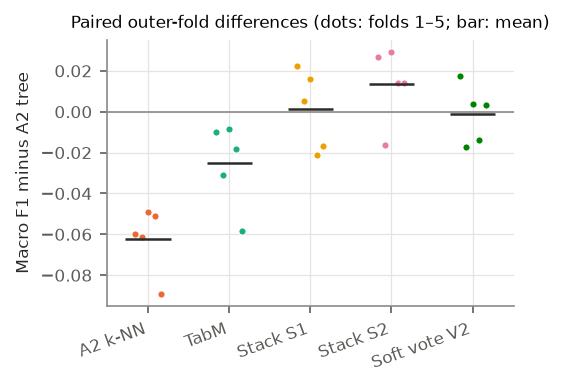

In [16]:
MODEL_NAMES = {"tree": "A2 tree", "knn": "A2 k-NN", "tabm": "TabM", "S1": "Stack S1", "S2": "Stack S2", "V2": "Soft vote V2"}
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "font.size": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e4e4e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8a86", "axes.labelcolor": "#2b2b29", "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
})


def save(fig, name):
    for suffix in ("pdf", "png"):
        fig.savefig(OUTPUT_DIR / f"ass4_{name}.{suffix}", bbox_inches="tight")


METRICS = {
    "macro_f1": lambda truth, pred: f1_score(truth, pred, average="macro"),
    "balanced_accuracy": balanced_accuracy_score,
    "accuracy": accuracy_score,
}
predictions = {key: predict_labels(proba) for key, proba in test_proba.items()}
fold_metrics = pd.DataFrame([
    {"model": model, "outer_fold": fold, **{name: score(y.loc[pred.index], pred) for name, score in METRICS.items()}}
    for (model, fold), pred in predictions.items()
])
fold_metrics.to_csv(OUTPUT_DIR / "ass4_fold_metrics.csv", index=False)
summary = fold_metrics.groupby("model")[list(METRICS)].agg(["mean", "std"]).reindex(list(MODEL_NAMES))
summary.index = summary.index.map(MODEL_NAMES)
summary.to_csv(OUTPUT_DIR / "ass4_summary.csv")
display(summary.round(4))

macro_by_fold = fold_metrics.pivot(index="outer_fold", columns="model", values="macro_f1")


def paired_comparison(model, reference):
    """Paired macro-F1 differences over the outer folds with a Wilcoxon and a corrected t-test."""
    difference = macro_by_fold[model] - macro_by_fold[reference]
    # Nadeau and Bengio: inflate the variance by n_test / n_train = 1 / (K - 1) for overlapping training sets.
    t = difference.mean() / np.sqrt((1 / len(difference) + 1 / (OUTER_FOLDS - 1)) * difference.var())
    return {
        "comparison": f"{MODEL_NAMES[model]} − {MODEL_NAMES[reference]}",
        "mean_difference": difference.mean(),
        "std": difference.std(),
        **{f"fold_{fold}": value for fold, value in difference.items()},
        "wilcoxon_p": stats.wilcoxon(difference).pvalue,
        "corrected_t_p": 2 * stats.t.sf(abs(t), len(difference) - 1),
    }


COMPARISONS = [(model, "tree") for model in ("knn", "tabm", "S1", "S2", "V2")] + [("S2", "V2"), ("S2", "S1"), ("S2", "tabm")]
paired = pd.DataFrame([paired_comparison(*pair) for pair in COMPARISONS]).set_index("comparison")
paired.to_csv(OUTPUT_DIR / "ass4_paired_tests.csv")
display(paired.round(4))

others = [model for model in MODEL_NAMES if model != "tree"]
fig, ax = plt.subplots(figsize=(3.5, 2.3))
jitter = np.linspace(-0.16, 0.16, OUTER_FOLDS)
for position, model in enumerate(others):
    difference = macro_by_fold[model] - macro_by_fold["tree"]
    ax.scatter(position + jitter, difference, s=12, color=MODEL_COLORS[model], edgecolor="white", linewidth=0.5, zorder=3)
    ax.hlines(difference.mean(), position - 0.28, position + 0.28, color="#2b2b29", linewidth=1.2, zorder=4)
ax.axhline(0, color="#8a8a86", linewidth=0.8)
ax.set_xticks(range(len(others)), [MODEL_NAMES[model] for model in others], rotation=20, ha="right")
ax.set_ylabel("Macro F1 minus A2 tree")
ax.set_title("Paired outer-fold differences (dots: folds 1–5; bar: mean)", fontsize=8)
save(fig, "paired_differences")
plt.show()

**Findings.**

- **Stack S2 is the only model above the A2 tree on average:** macro F1 0.588 ± 0.024 against
  0.575 ± 0.017, a gain of 0.014 that holds on four of five folds (fold 2: −0.016). Neither
  test finds it significant (Wilcoxon *p* = 0.31, corrected *t* *p* = 0.32). It also has the
  highest balanced accuracy (0.591) and accuracy (0.821).
- **TabM alone** scores 0.550 ± 0.010, below the tree on all five folds (−0.025; Wilcoxon
  *p* = 0.0625, the smallest value five folds allow; corrected *t* *p* = 0.14). Its accuracy
  is higher than the tree's (0.818 against 0.811) but its balanced accuracy is lower (0.527
  against 0.583): it favours the large classes. It is also the most stable model across folds.
- **S1 (0.576) and V2 (0.573) only match the tree.** Combining the two A2 models, learned or
  averaged, gains nothing, because k-NN is weaker than the tree almost everywhere.
- **Q5:** S2 beats soft voting V2 on all five folds (+0.015 ± 0.011; Wilcoxon *p* = 0.0625,
  corrected *t* *p* = 0.12). Learning the combination helps, as predicted, with the usual
  five-fold caveat.
- **Q6 (score):** adding TabM lifts the stack from S1 to S2 by 0.0125, positive on four of five
  folds, not significant. Section 6.4 measures the diversity behind this.

## 6.2 Per-class results and conflicting labels (Q9)

Class F1 uses pooled outer-test predictions. The comparison reports absolute observed gains
over the earlier tree, with no derived performance benchmark.


In [ ]:
pooled = {model: pd.concat([predictions[model, fold] for fold in FOLDS]) for model in MODEL_NAMES}
per_class = pd.DataFrame(
    {MODEL_NAMES[model]: f1_score(y.loc[pred.index], pred, labels=CLASS_ORDER, average=None) for model, pred in pooled.items()},
    index=CLASS_ORDER,
)
per_class.index.name = "attack_class"
per_class.to_csv(OUTPUT_DIR / "ass4_per_class_f1.csv")
display(per_class.round(3))

HARD_CLASSES = ["Backdoor", "DoS", "Analysis"]
ensembles = [MODEL_NAMES[model] for model in ("tabm", "S1", "S2", "V2")]
conflict_class_comparison = pd.DataFrame({
    "a2_tree": per_class.loc[HARD_CLASSES, "A2 tree"],
    "best_model": per_class.loc[HARD_CLASSES].idxmax(axis=1),
    "best_f1": per_class.loc[HARD_CLASSES].max(axis=1),
    "best_ensemble": per_class.loc[HARD_CLASSES, ensembles].idxmax(axis=1),
    "best_ensemble_f1": per_class.loc[HARD_CLASSES, ensembles].max(axis=1),
})
conflict_class_comparison["gain"] = conflict_class_comparison["best_f1"] - conflict_class_comparison["a2_tree"]
conflict_class_comparison.to_csv(OUTPUT_DIR / "ass4_conflict_class_comparison.csv")
display(conflict_class_comparison.round(3))

shown = ["tree", "knn", "tabm", "S2"]
fig, ax = plt.subplots(figsize=(3.5, 3.3))
positions = np.arange(len(CLASS_ORDER))[::-1]
for offset, model in zip(np.linspace(-0.27, 0.27, len(shown)), shown):
    ax.scatter(per_class[MODEL_NAMES[model]], positions + offset, s=14, color=MODEL_COLORS[model],
               edgecolor="white", linewidth=0.5, label=MODEL_NAMES[model], zorder=3)
ax.set_yticks(positions, CLASS_ORDER)
ax.set_xlim(0, 1.02)
ax.set_xlabel("F1 (pooled outer folds)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=4, frameon=False, fontsize=6.5, handletextpad=0.2, columnspacing=0.8)
save(fig, "per_class_f1")
plt.show()

best_ensemble = summary.loc[ensembles, ("macro_f1", "mean")].idxmax()
best_key = next(model for model, name in MODEL_NAMES.items() if name == best_ensemble)
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.3), sharey=True)
for ax, model in zip(axes, ("tree", best_key)):
    matrix = confusion_matrix(y.loc[pooled[model].index], pooled[model], labels=CLASS_ORDER, normalize="true")
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=1)
    for (row, col), value in np.ndenumerate(matrix):
        if value >= 0.005:
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=5,
                    color="white" if value > 0.55 else "#2b2b29")
    ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=60, ha="right")
    ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    ax.set_xlabel("Predicted class")
    ax.set_title(f"{MODEL_NAMES[model]} (rows sum to 1)", fontsize=8)
    ax.grid(False)
axes[0].set_ylabel("True class")
save(fig, "confusion_matrices")
plt.show()


**Findings (Q9, first run).**

The best ensemble gained 0.028 F1 on Backdoor and 0.007 on Analysis. Soft vote V2 reached
DoS F1 0.413 against the tree's 0.311, but k-NN and TabM already scored about 0.403 and
0.409. S2 improved DoS but lost Worms F1, 0.450 against 0.598. A combination therefore did
not improve every attack class, and useful base-learner information differed by class.


## 6.3 TabM tuning questions (Q1–Q4)

All values are hold-out macro F1, mean ± standard deviation over the five outer folds. The
*k* = 32 point is each fold's stage-1 winner, from which the stage-2 variants differ by one
factor. "Mean member F1" is the average macro F1 of the *k* members on their own; the gap
between it and the ensemble's F1 is the gain from combining them.

val_macro_f1         mean_member_f1         epochs           seconds  \
           mean     std           mean     std   mean      std     mean   
k                                                                         
1        0.5360  0.0125         0.5360  0.0125   11.2   5.2631  11.0382   
4        0.5442  0.0157         0.5412  0.0143   25.6  18.7963  20.6144   
8        0.5395  0.0162         0.5325  0.0208   17.4  10.2859  16.5510   
32       0.5496  0.0044         0.5434  0.0035   25.2   4.8166  36.9880   

             
        std  
k            
1    5.6163  
4   15.3214  
8   10.9940  
32  21.9425

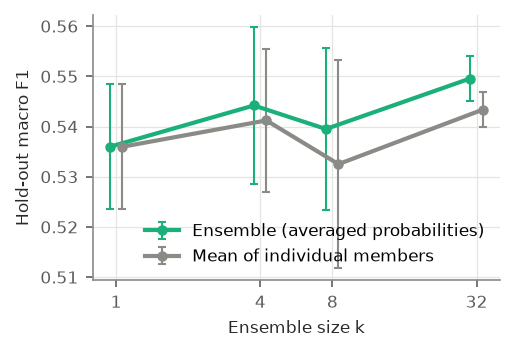

,unweighted,class_weighted,difference
Normal,0.915,0.836,-0.078
Reconnaissance,0.832,0.813,-0.019
Backdoor,0.147,0.172,0.025
DoS,0.362,0.474,0.112
Exploits,0.720,0.584,-0.136
Analysis,0.073,0.165,0.092
Fuzzers,0.571,0.584,0.012
Worms,0.290,0.068,-0.222
Shellcode,0.598,0.396,-0.202
Generic,0.987,0.986,-0.001


,shared,distinct,shared_member_f1,distinct_member_f1,difference
outer_fold,,,,,
1,0.5550,0.5351,0.5456,0.5283,-0.0199
2,0.5477,0.5253,0.5449,0.5222,-0.0224
3,0.5437,0.5210,0.5371,0.5179,-0.0227
4,0.5526,0.5499,0.5449,0.5436,-0.0027
5,0.5488,0.5400,0.5443,0.5351,-0.0088


val_macro_f1   epochs
factor   value                         
d_block  256.000        0.5295  21.4833
         512.000        0.5355  15.6167
n_blocks 2.000          0.5304  17.6667
         3.000          0.5346  19.4333
dropout  0.000          0.5316  11.9500
         0.100          0.5359  21.0000
         0.200          0.5299  22.7000
lr       0.001          0.5313  19.7333
         0.002          0.5337  17.3667

In [18]:
capacity = tabm_tuning[tabm_tuning["question"] == "Q4 capacity"]
stage1_best = capacity.loc[capacity.groupby("outer_fold")["val_macro_f1"].idxmax()]
by_question = {question: group.set_index("outer_fold") for question, group in tabm_tuning.groupby("question")}

k_sweep = (
    pd.concat([stage1_best, by_question["Q1 ensemble size"].reset_index()])
    .groupby("k")[["val_macro_f1", "mean_member_f1", "epochs", "seconds"]]
    .agg(["mean", "std"])
)
k_sweep.to_csv(OUTPUT_DIR / "ass4_q1_k_sweep.csv")
display(k_sweep.round(4))

fig, ax = plt.subplots(figsize=(3.5, 2.3))
for column, label, color, dodge in (
    ("val_macro_f1", "Ensemble (averaged probabilities)", MODEL_COLORS["tabm"], 0.94),
    ("mean_member_f1", "Mean of individual members", "#8a8a86", 1.06),
):
    ax.errorbar(k_sweep.index * dodge, k_sweep[column, "mean"], yerr=k_sweep[column, "std"], marker="o", markersize=4,
                linewidth=2, elinewidth=1, capsize=2, color=color, label=label)
ax.set_xscale("log", base=2)
ax.set_xticks(k_sweep.index, [str(k) for k in k_sweep.index])
ax.set_xlim(0.8, 40)
ax.set_xlabel("Ensemble size k")
ax.set_ylabel("Hold-out macro F1")
ax.legend(frameon=False, loc="lower right")
save(fig, "tabm_k_sweep")
plt.show()

class_columns = [f"val_f1_{name}" for name in CLASS_ORDER]
reference = stage1_best.set_index("outer_fold")
class_weighting = pd.DataFrame({
    "unweighted": reference[class_columns].mean().to_numpy(),
    "class_weighted": by_question["Q2 class weights"][class_columns].mean().to_numpy(),
}, index=CLASS_ORDER)
class_weighting.loc["macro F1"] = [reference["val_macro_f1"].mean(), by_question["Q2 class weights"]["val_macro_f1"].mean()]
class_weighting["difference"] = class_weighting["class_weighted"] - class_weighting["unweighted"]
class_weighting.to_csv(OUTPUT_DIR / "ass4_q2_class_weights.csv")
display(class_weighting.round(3))

batches = pd.DataFrame({
    "shared": reference["val_macro_f1"],
    "distinct": by_question["Q3 distinct batches"]["val_macro_f1"],
    "shared_member_f1": reference["mean_member_f1"],
    "distinct_member_f1": by_question["Q3 distinct batches"]["mean_member_f1"],
})
batches["difference"] = batches["distinct"] - batches["shared"]
batches.to_csv(OUTPUT_DIR / "ass4_q3_batches.csv")
display(batches.round(4))

capacity_effects = pd.concat({
    factor: capacity.groupby(factor)[["val_macro_f1", "epochs"]].mean()
    for factor in ("d_block", "n_blocks", "dropout", "lr")
}, names=["factor", "value"])
capacity_effects.to_csv(OUTPUT_DIR / "ass4_q4_capacity_effects.csv")
display(capacity_effects.round(4))

**Findings.**

- **Q1 (ensemble size).** Hold-out macro F1 rises from 0.536 at *k* = 1 to 0.550 at *k* = 32,
  but not monotonically (*k* = 4: 0.544; *k* = 8: 0.540), and the fold-to-fold standard
  deviations (0.004–0.016) are as large as the steps. The *k* = 32 point is the best of 24
  capacity candidates, so it is biased upwards relative to the single fits at *k* ∈ {1, 4, 8}.
  The ensemble's gain over its own average member is small (0.006 at *k* = 32). The clearest
  effect of *k* is stability: the standard deviation falls from 0.013 at *k* = 1 to 0.004 at
  *k* = 32. The prediction that most of the gain arrives by *k* = 8 cannot be confirmed: the
  gain is too small to locate.
- **Q2 (class weights).** Balanced weights lower hold-out macro F1 from 0.550 to 0.508. They
  raise DoS (+0.11), Analysis (+0.09) and Backdoor (+0.03) but cut Worms (−0.22), Shellcode
  (−0.20), Exploits (−0.14) and Normal (−0.08). The prediction is refuted for exactly the
  classes it named. Worms rows weigh about 150 times as much as an average row, which makes
  over-predicting the rare classes cheap; lost precision is the likely mechanism, although
  precision was not measured here. The classes that gain are those where the tree is weakest
  and conflicts are most common.
- **Q3 (shared or distinct batches).** Distinct, bagging-style batches are worse on all five
  folds (−0.003 to −0.023, mean −0.015), and their members are individually worse too (mean
  member F1 0.529 against 0.543). The prediction of "little difference" is refuted. This
  agrees with the TabM authors' default of shared batches. A plausible explanation is that
  the random-sign initialisation of **r** already makes the members diverse, so distinct
  batches add gradient noise to the shared weights without adding useful diversity.
- **Q4 (capacity).** Every factor moves mean hold-out F1 by less than 0.007: width 512 against
  256 (0.536 against 0.530), depth 3 against 2 (0.535 against 0.530), learning rate 2e-3 against
  1e-3 (0.534 against 0.531), dropout 0.1 against 0 against 0.2 (0.536, 0.532, 0.530). Moderate
  dropout helps slightly and stronger dropout does not, so the evidence that label conflicts
  favour strong regularisation is weak. Early stopping does most of the regularising: without
  dropout the best epoch averages 12, against 21–23 with dropout.

## 6.4 Stacking questions (Q5–Q8)

Q5 and Q6 compare scores in the paired-test table of Section 6.1. Below, base-learner
diversity is measured on the outer test folds: the correlation between two learners' error
indicators (1 if a row is misclassified), how often they predict different labels, and how
often both are wrong. Low error correlation is what lets a combiner improve on its members.

In [19]:
diversity_rows = []
for a, b in itertools.combinations(STACKS["S2"], 2):
    for fold in FOLDS:
        truth = y.loc[predictions[a, fold].index]
        error_a, error_b = predictions[a, fold].ne(truth), predictions[b, fold].ne(truth)
        diversity_rows.append({
            "pair": f"{MODEL_NAMES[a]} / {MODEL_NAMES[b]}",
            "error_correlation": np.corrcoef(error_a, error_b)[0, 1],
            "disagreement": predictions[a, fold].ne(predictions[b, fold]).mean(),
            "both_wrong": (error_a & error_b).mean(),
        })
diversity = pd.DataFrame(diversity_rows).groupby("pair").agg(["mean", "std"])
diversity.to_csv(OUTPUT_DIR / "ass4_q6_diversity.csv")
display(diversity.round(3))

meta_search = pd.concat(meta_search_rows, ignore_index=True)
meta_search["representation"] = meta_search["params"].map(lambda params: params["features__kw_args"]["kind"])
meta_search.assign(params=meta_search["params"].astype(str)).to_csv(OUTPUT_DIR / "ass4_meta_tuning.csv", index=False)
representation = (
    meta_search.groupby(["stack", "outer_fold", "representation"])["mean_test_score"].max()
    .groupby(["stack", "representation"]).agg(["mean", "std"]).unstack("stack")
)
representation.to_csv(OUTPUT_DIR / "ass4_q8_representation.csv")
display(representation.round(4))
selected_meta = (
    meta_search[meta_search["rank_test_score"] == 1].drop_duplicates(["stack", "outer_fold"])
    .assign(C=lambda frame: frame["params"].map(lambda params: params["model__C"]),
            class_weight=lambda frame: frame["params"].map(lambda params: params["model__class_weight"] or "none"))
    .set_index(["stack", "outer_fold"])[["representation", "C", "class_weight", "mean_test_score"]]
)
selected_meta.to_csv(OUTPUT_DIR / "ass4_meta_selected.csv")
display(selected_meta)

error_correlation        disagreement        both_wrong  \
                               mean    std         mean    std       mean   
pair                                                                        
A2 k-NN / A2 tree             0.514  0.033        0.205  0.025      0.123   
A2 k-NN / TabM                0.555  0.025        0.186  0.019      0.127   
A2 tree / TabM                0.605  0.047        0.149  0.029      0.126   

                          
                     std  
pair                      
A2 k-NN / A2 tree  0.011  
A2 k-NN / TabM     0.003  
A2 tree / TabM     0.004

mean             std        
stack               S1      S2      S1      S2
representation                                
log_proba       0.5352  0.5473  0.0139  0.0116
one_hot         0.5374  0.5525  0.0146  0.0144
proba           0.5556  0.5639  0.0085  0.0070

representation      C class_weight  mean_test_score
stack outer_fold                                                    
S1    1                   proba  10.00         none         0.547680
      2                   proba  10.00         none         0.562864
      3                   proba  10.00         none         0.565343
      4                   proba   0.01         none         0.555121
      5                 one_hot   0.01     balanced         0.556598
S2    1                   proba   1.00         none         0.559544
      2                 one_hot   0.01     balanced         0.574777
      3                   proba   0.10         none         0.571342
      4                   proba   0.01         none         0.557910
      5                   proba   1.00         none         0.559132

**Findings.**

- **Q6 (diversity): prediction refuted.** TabM's errors correlate *more* with the tree's
  (0.605) than k-NN's do (0.514), and TabM disagrees with the tree on 14.9% of rows against
  k-NN's 20.5%. k-NN is the most diverse learner but also the weakest. S2 still beats S1, so
  TabM contributes accuracy and better-graded probabilities rather than diversity. Every pair
  of learners is wrong together on about 12.5% of rows, which no combination of that pair can
  fix.
- **Q8 (representation).** Raw probabilities give the best inner macro F1 for both stacks (S1
  0.556, S2 0.564). One-hot labels follow (0.537, 0.553) and log-probabilities come last
  (0.535, 0.547). Probabilities are selected in 8 of 10 stack–fold combinations. One-hot
  labels discard confidence, as predicted. Log-probabilities do worst because k-NN's
  probabilities are mostly exactly 0 or 1: the logarithm maps them to two extreme values
  (−9.2 and 0) and exaggerates the coarsest learner. The meta-learner selects no class
  weighting in 8 of 10 cases. C ranges from 0.01 to 10 across folds, so the inner score is
  nearly flat in C.

**Meta-learner coefficients (Q7).** For each class *c*, the heatmap shows the coefficient
that the S2 meta-learner gives to each base learner's own score for class *c* in the logit of
class *c*, averaged over the five outer folds. A larger value means the meta-learner trusts
that learner more when it votes for that class. Coefficients are comparable across learners
within a fold; if folds selected different representations, the average mixes scales, so
the selected representations above should be read alongside it.

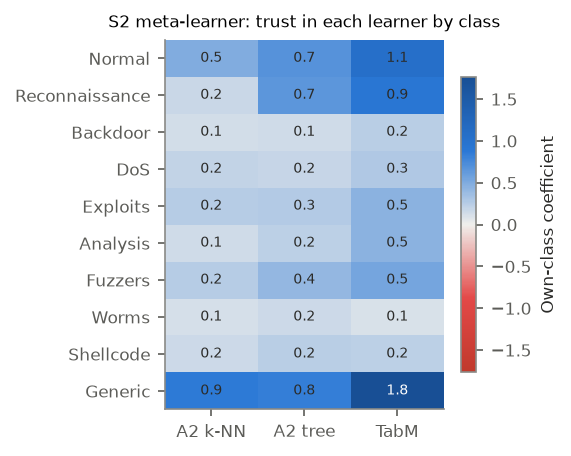

In [20]:
own_class = pd.DataFrame(
    {
        MODEL_NAMES[learner]: [
            np.mean([meta_coefficients["S2", fold].loc[name, f"{learner}:{name}"] for fold in FOLDS]) for name in CLASS_ORDER
        ]
        for learner in STACKS["S2"]
    },
    index=CLASS_ORDER,
)
own_class.to_csv(OUTPUT_DIR / "ass4_q7_meta_coefficients.csv")

diverging = LinearSegmentedColormap.from_list("diverging", ["#c0392b", "#e34948", "#f0efec", "#2a78d6", "#184f95"])
limit = np.abs(own_class.to_numpy()).max()
fig, ax = plt.subplots(figsize=(3.0, 3.2))
image = ax.imshow(own_class, cmap=diverging, vmin=-limit, vmax=limit, aspect="auto")
for (row, col), value in np.ndenumerate(own_class.to_numpy()):
    ax.text(col, row, f"{value:.1f}", ha="center", va="center", fontsize=6.5,
            color="white" if abs(value) > 0.6 * limit else "#2b2b29")
ax.set_xticks(range(own_class.shape[1]), own_class.columns)
ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Own-class coefficient")
ax.set_title("S2 meta-learner: trust in each learner by class", fontsize=8)
save(fig, "meta_coefficients")
plt.show()

**Finding (Q7): prediction refuted.** On DoS the S2 meta-learner gives k-NN the same weight
as the tree (0.19 and 0.19) and less than TabM (0.29). On Analysis k-NN gets the smallest
weight (0.15, against 0.23 for the tree and 0.45 for TabM). TabM has the largest own-class
coefficient for 8 of 10 classes; the exceptions are Worms and Shellcode, where the tree
leads. This agrees with Q6: once TabM is present, k-NN's DoS advantage is redundant, because
TabM is as good on DoS (0.409 against 0.403). Caveats: these are standardised own-class
coefficients averaged over folds; fold 2 used one-hot inputs; and cross-class coefficients
also contribute to each logit.

## 6.5 Computational cost

Seconds per outer fold. Out-of-fold cost covers the three inner fits and the outer-train refit
(four fits); TabM tuning covers all 29 candidates of one fold.

In [21]:
cost = pd.Series(oof_seconds).groupby(level=0).mean().rename("oof_seconds_per_fold").to_frame()
cost.loc["tabm", "tuning_seconds_per_fold"] = tabm_tuning.groupby("outer_fold")["seconds"].sum().mean()
cost.index = cost.index.map(MODEL_NAMES)
cost.to_csv(OUTPUT_DIR / "ass4_cost.csv")
display(cost.round(0))

,oof_seconds_per_fold,tuning_seconds_per_fold
A2 k-NN,676.0,NaN
TabM,114.0,864.0
A2 tree,19.0,NaN


**Finding.** k-NN dominates the cost of stacking: 676 s per fold for its four CPU fits,
against 114 s for TabM's four GPU fits and 19 s for the tree. TabM tuning (29 candidates)
adds 864 s per fold, and the meta-learner search about 15 s. S2's gain of 0.014 macro F1 over
the tree therefore costs about 28 minutes per outer fold, against about 3 seconds to fit
the tree alone.

# Summary: answers to the questions set before evaluation

| # | Prediction | Outcome | Evidence |
|---|---|---|---|
| Q1 | Most of the gain from ensemble size arrives by *k* = 8 | Not confirmed | Hold-out F1 0.536 (*k* = 1) → 0.550 (*k* = 32), not monotone, steps within noise; the main effect is lower variance |
| Q2 | Class weights raise Worms and Shellcode F1 | Refuted | Macro F1 −0.042; Worms −0.22, Shellcode −0.20; DoS, Analysis, Backdoor rise |
| Q3 | Distinct batches make little difference | Refuted (they hurt) | Worse on all five folds, mean −0.015 |
| Q4 | Dropout > 0 wins; capacity matters little | Weakly supported | Dropout 0.1 best by 0.004; every factor moves F1 by less than 0.007 |
| Q5 | S2 beats soft voting V2 | Supported | +0.015, all five folds positive (Wilcoxon *p* = 0.0625) |
| Q6 | TabM adds diversity | Score: yes; diversity: refuted | S2 − S1 = +0.0125 (4/5 folds); TabM–tree error correlation 0.605 > k-NN–tree 0.514 |
| Q7 | Meta-learner trusts k-NN on DoS and Analysis | Refuted | TabM gets the largest own-class weight on both and on 8 of 10 classes |
| Q8 | Probabilities or log-probabilities beat one-hot | Half supported | Probabilities best; log-probabilities worst |
| Q9 | Changes on Backdoor, DoS and Analysis | Mixed | Best gains: Backdoor 0.028, Analysis 0.007 and DoS about 0.101 |

**Overall.** Stack S2 (k-NN + tree + TabM, logistic-regression meta-learner on probabilities)
is the best model: macro F1 0.588 ± 0.024 against the A2 tree's 0.575 ± 0.017, better on four
of five folds but not significantly so with five folds. TabM alone does not beat the tree.
Its value is inside the stack, where it supplies accurate, well-graded probabilities.
Combining only the two Assignment 2 models gains nothing. 